In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Model evaluation
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,precision_score,recall_score,f1_score)

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("Loan_approval_dataset.csv")

In [3]:
df

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [4]:
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [5]:
df.shape

(4269, 13)

In [6]:
df.columns

Index(['loan_id', 'no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='str')

In [7]:
# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

In [8]:
# Display cleaned column names
df.columns

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='str')

In [9]:
df.isnull().sum()

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   loan_id                   4269 non-null   int64
 1   no_of_dependents          4269 non-null   int64
 2   education                 4269 non-null   str  
 3   self_employed             4269 non-null   str  
 4   income_annum              4269 non-null   int64
 5   loan_amount               4269 non-null   int64
 6   loan_term                 4269 non-null   int64
 7   cibil_score               4269 non-null   int64
 8   residential_assets_value  4269 non-null   int64
 9   commercial_assets_value   4269 non-null   int64
 10  luxury_assets_value       4269 non-null   int64
 11  bank_asset_value          4269 non-null   int64
 12  loan_status               4269 non-null   str  
dtypes: int64(10), str(3)
memory usage: 531.6 KB


In [12]:
# Count loan status
df['loan_status'].value_counts()

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

In [13]:
# Percentage distribution
df['loan_status'].value_counts(normalize=True) * 100

loan_status
Approved    62.215976
Rejected    37.784024
Name: proportion, dtype: float64

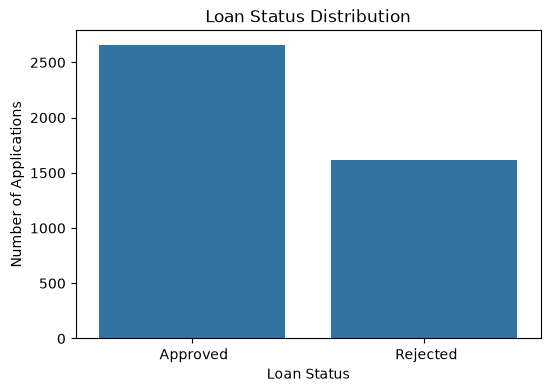

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(x='loan_status', data=df)

plt.title('Loan Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applications')

plt.show()

In [15]:
# Independent variables
X = df.drop(['loan_status', 'loan_id'], axis=1) 
# Here we excluded loan_id from X because it is only an identification number, not a meaningful predictive feature. 

# Dependent variable
y = df['loan_status']

In [16]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4269, 11)
y shape: (4269,)


In [17]:
# Identify numerical columns
num_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Identify categorical columns
cat_cols = X.select_dtypes(include=['object', 'str']).columns

print("Numerical Columns:")
print(list(num_cols))

print("\nCategorical Columns:")
print(list(cat_cols))

print("\nTotal Numerical Columns:", len(num_cols))
print("Total Categorical Columns:", len(cat_cols))

Numerical Columns:
['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']

Categorical Columns:
['education', 'self_employed']

Total Numerical Columns: 9
Total Categorical Columns: 2


In [18]:
# Encode target variable
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(y)

print("Target classes:", le.classes_)    # le.classes_ returns the original unique categories that LabelEncoder learned, in the order used for encoding.
print("Encoded target values:", np.unique(y))

Target classes: [' Approved' ' Rejected']
Encoded target values: [0 1]


In [19]:
# In Scikit-learn, attributes ending with an underscore (_) often represent values learned during model fitting. 
# Examples include classes_, feature_importances_ and coef_.

In [20]:
# Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.20,random_state=42,stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (3415, 11)
X_test shape: (854, 11)
y_train shape: (3415,)
y_test shape: (854,)


In [21]:
# dataset contains two types of independent features:1) Numerical columns (9), 2) Categorical columns (2)
# so we use Data Preprocessing using Pipeline and ColumnTransformer.

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[('scaler', StandardScaler())])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[('onehot', OneHotEncoder(handle_unknown='ignore'))])

# Combine both preprocessors
preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, num_cols),('cat', categorical_transformer, cat_cols)])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [22]:
# I used Pipeline to organize numerical preprocessing. I applied StandardScaler to standardize numerical features so that algorithms such as 
# Logistic Regression, KNN and SVM can work effectively with features having different scales."
# StandardScaler - 	Standardizes numerical features
# OneHotEncoder - Converts categorical features into numerical values
# ColumnTransformer - Applies different preprocessing to different columns
# Pipeline - Organizes preprocessing steps
# steps is a parameter of Pipeline.It accepts a list of operations that should be performed sequentially.
# ColumnTransformer Combines the transformed features

In [23]:
# Define Machine Learning models
# we will create a dictionary containing our six classification algorithms.
# It allows us to train and compare all six algorithms systematically using a loop instead of writing separate training code for every model.
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(),
    'XGBoost': XGBClassifier(random_state=42,eval_metric='logloss')
}

print("All 6 ML models are defined successfully!")

All 6 ML models are defined successfully!


In [24]:
# Train all six ML models

trained_models = {}    # Creates an empty dictionary

for name, model in models.items():   # models.items () Accesses model names and algorithms

    # Create pipeline
    clf = Pipeline(steps=[('preprocessor', preprocessor),('classifier', model)])   # pipeline conbines preprocessing and classifier

    # Train model
    clf.fit(X_train, y_train)   # Trains the current model

    # Store trained model
    trained_models[name] = clf   # Stores the trained model

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!
SVM trained successfully!
XGBoost trained successfully!


In [25]:
# Evaluate all six models

results = []           # creates an empty Python list.

for name, model in trained_models.items():

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({'Model': name,'Accuracy': accuracy,'Precision': precision,'Recall': recall,'F1 Score': f1})

# Create performance comparison table
results_df = pd.DataFrame(results)    # converting the Python list into a Pandas DataFrame.

results_df = results_df.sort_values(by='F1 Score', ascending=False)  # sort is used to see which model has the best F1 Score at the top of the table.

results_df   

,Model,Accuracy,Precision,Recall,F1 Score
5,XGBoost,0.981265,0.984227,0.965944,0.975000
2,Random Forest,0.981265,0.990415,0.959752,0.974843
1,Decision Tree,0.973068,0.971698,0.956656,0.964119
4,SVM,0.944965,0.942308,0.910217,0.925984
0,Logistic Regression,0.922717,0.915858,0.876161,0.895570
3,KNN,0.900468,0.886364,0.845201,0.865293


In [26]:
results_df = results_df.sort_values(by='F1 Score',ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,XGBoost,0.981265,0.984227,0.965944,0.975000
1,Random Forest,0.981265,0.990415,0.959752,0.974843
2,Decision Tree,0.973068,0.971698,0.956656,0.964119
3,SVM,0.944965,0.942308,0.910217,0.925984
4,Logistic Regression,0.922717,0.915858,0.876161,0.895570
5,KNN,0.900468,0.886364,0.845201,0.865293


In [27]:
# Random Forest is also very close, with slightly higher precision (99.04%) but marginally lower F1-score.
# XGBoost achieved the highest F1-score.
# We Select XGBoost as the current best model based on F1-score. We should also validate it further before finalizing.

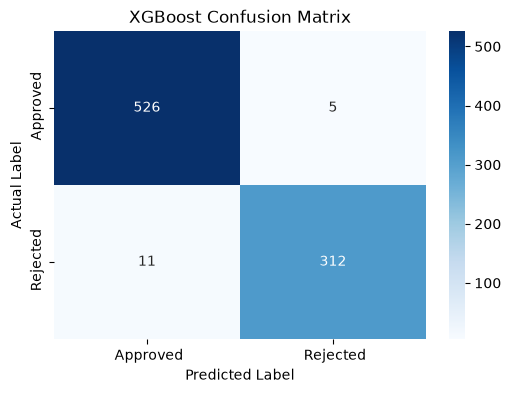

In [28]:
# Best model
best_model = trained_models['XGBoost']

# Predict test data
y_pred_best = best_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred_best)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=le.classes_,yticklabels=le.classes_)

plt.title('XGBoost Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.show()

In [29]:
# overall performance
# Total correct predictions = 526 + 312 = 838
# Total incorrect predictions = 5 + 11 = 16
# Total test records = 854
# Accuracy = 98.13%
# This is a strong result on test dataset.

In [30]:
# Classification Report

print("XGBoost Classification Report")

print(classification_report(y_test,y_pred_best,target_names=le.classes_))

XGBoost Classification Report
              precision    recall  f1-score   support

    Approved       0.98      0.99      0.99       531
    Rejected       0.98      0.97      0.97       323

    accuracy                           0.98       854
   macro avg       0.98      0.98      0.98       854
weighted avg       0.98      0.98      0.98       854



In [31]:
# Approved recall is 99%: the model identifies almost all approved applications.
# Rejected recall is 97%: the model identifies almost all rejected applications.
# Both classes have strong F1-scores.
# Overall accuracy is approximately 98%.

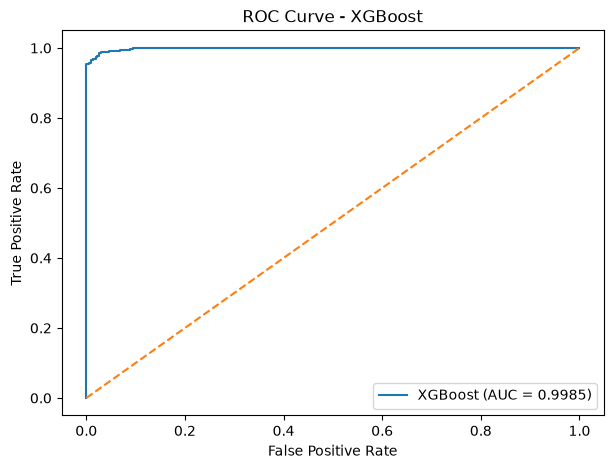

XGBoost AUC Score: 0.9984782494621399


In [32]:
from sklearn.metrics import roc_curve, roc_auc_score

# Get prediction probabilities
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate ROC and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC Curve
plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr, label=f'XGBoost (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost')
plt.legend()
plt.show()

print("XGBoost AUC Score:", auc_score)

In [33]:
# AUC = 1.0: Perfect class separation.
# AUC = 0.5: Similar to random guessing.
# AUC = 0.9985: Excellent ability to distinguish between Approved and Rejected applications.

In [34]:
from sklearn.model_selection import cross_val_score

# Create XGBoost pipeline
xgb_cv_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ))
])

# 5-fold cross-validation
cv_scores = cross_val_score(
    xgb_cv_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

# Display results
print("Cross-validation scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())
print("Standard Deviation:", cv_scores.std())

Cross-validation scores: [0.98126464 0.98711944 0.9824356  0.98360656 0.985932  ]
Mean CV Accuracy: 0.9840716468395057
Standard Deviation: 0.0021689736193371877


In [35]:
# All five folds have accuracy above 98%.
# The mean accuracy is 98.41%.
# The low standard deviation indicates consistent performance across the five folds.

In [36]:
import joblib

# Save the complete trained model
joblib.dump(best_model, 'loan_approval_model.pkl')

print("XGBoost model saved successfully!")

XGBoost model saved successfully!
